## NLP Sentiment Analysis on E-commerce Customer Reviews

In [1]:
## Problem Statement

## Customer reviews play an important role in helping businesses understand customer satisfaction and improve their products..
## Manually reading thousands of reviews is time-consuming and inefficient..
## Sentiment Analysis, a Natural Language Processing (NLP) technique, helps automate this process by classifying customer opinions into different sentiment categories..

## The objective of this project is to build a machine learning model that can automatically predict the sentiment of customer reviews collected from an e-commerce platform..
## The dataset contains review titles, customer ratings and detailed review texts..
## Since explicit sentiment labels are not available, they will be created from customer ratings during the project..
## The final model will be deployed as a Streamlit web application for real-time sentiment prediction..

In [2]:
## Lets import required libraries..

## Data manipulation..
import pandas as pd
import numpy as np

## Data visualization..
import matplotlib.pyplot as plt
import seaborn as sns

## Ignore warnings.. 
import warnings
warnings.filterwarnings("ignore")

## Display settings..
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

### Load the Dataset

In [3]:
## Load the dataset..

df = pd.read_excel("dataset.xlsx")

## Display the first 5 rows..
df.head()

,title,rating,body
0,Horrible product,1,Very disappointed with the overall performance...
1,Camera quality is not like 48 megapixel,3,Camera quality is low
2,Overall,4,"Got the mobile on the launch date,Battery must..."
3,A big no from me,1,1. It doesn't work with 5.0GHz WiFi frequency....
4,Put your money somewhere else,1,"Not worth buying....faulty software, poor disp..."


### Dataset Shape

In [4]:
## Check the number of rows and columns..

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Dataset shape:", df.shape)

Number of rows: 1440
Number of columns: 3
Dataset shape: (1440, 3)


### Check Column Names

In [5]:
# Display column names

print("Column names:")
print(df.columns.tolist())

Column names:
['title', 'rating', 'body']


### Check Data Types

In [6]:
## Check data types of all columns..

df.dtypes

title     object
rating     int64
body      object
dtype: object

### Basic Dataset Information

In [7]:
## Display basic information about the dataset..

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1440 entries, 0 to 1439
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   title   1440 non-null   object
 1   rating  1440 non-null   int64 
 2   body    1440 non-null   object
dtypes: int64(1), object(2)
memory usage: 33.9+ KB


### Check Missing Values

In [8]:
## Check missing values in each column..

df.isnull().sum()

title     0
rating    0
body      0
dtype: int64

In [9]:
## Calculate missing-value percentage..

missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_percentage

title     0.0
rating    0.0
body      0.0
dtype: float64

### Check Duplicate Rows

In [10]:
## Check the number of completely duplicated rows..

duplicate_rows = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_rows)

Number of duplicate rows: 0


### Check Duplicate Review Bodies

In [11]:
## Since body contains the actual review, lets separately check whether the same review appears more than once..
## Check duplicate review bodies..

duplicate_bodies = df["body"].duplicated().sum()

print("Number of duplicate review bodies:", duplicate_bodies)

Number of duplicate review bodies: 0


### Check Duplicate Titles

In [12]:
## Check duplicate review titles..

duplicate_titles = df["title"].duplicated().sum()

print("Number of duplicate titles:", duplicate_titles)

## Repeated title does not automatically mean that the entire review is duplicated..

Number of duplicate titles: 89


### Check Empty or Blank Reviews

In [13]:
## Missing values and blank strings are different things, so let's check them separately..
## Check for empty or whitespace-only review bodies..

empty_bodies = df["body"].astype(str).str.strip().eq("").sum()

print("Number of empty/blank review bodies:", empty_bodies)

Number of empty/blank review bodies: 0


In [14]:
## Check for empty or whitespace-only titles..

empty_titles = df["title"].astype(str).str.strip().eq("").sum()

print("Number of empty/blank review titles:", empty_titles)

Number of empty/blank review titles: 0


### Check Rating Values

In [15]:
## Check unique rating values..

print("Unique ratings:")
print(sorted(df["rating"].unique()))

Unique ratings:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


### Dataset Overview

In [16]:
## The dataset contains 1440 customer reviews collected from an e-commerce platform..
## It consists of three columns: title, rating and body..
## The title and body columns contain textual information provided by customers..
## while the rating column represents the numerical rating given by the customer on a scale of 1 to 5..

## Both title and body are stored as object data types while the rating column is stored as an integer..
## All three columns contain 1440 non-null values which means there are no missing values in the dataset..

## The dataset contains 0 duplicate rows and 0 duplicate review bodies..
## However there are 89 duplicate titles. Since the review bodies do not contain duplicates these repeated titles do not necessarily represent duplicate reviews..

## There are also 0 empty or blank review bodies and 0 empty or blank review titles..
## The rating column contains five unique values: 1, 2, 3, 4 and 5..

In [17]:
## Count the number of reviews for each rating..

rating_counts = df["rating"].value_counts().sort_index()

print(rating_counts)

rating
1    386
2    126
3    199
4    310
5    419
Name: count, dtype: int64


In [18]:
## Calculate rating percentages..

rating_percentage = (rating_counts / len(df)) * 100

print(rating_percentage.round(2))

rating
1    26.81
2     8.75
3    13.82
4    21.53
5    29.10
Name: count, dtype: float64


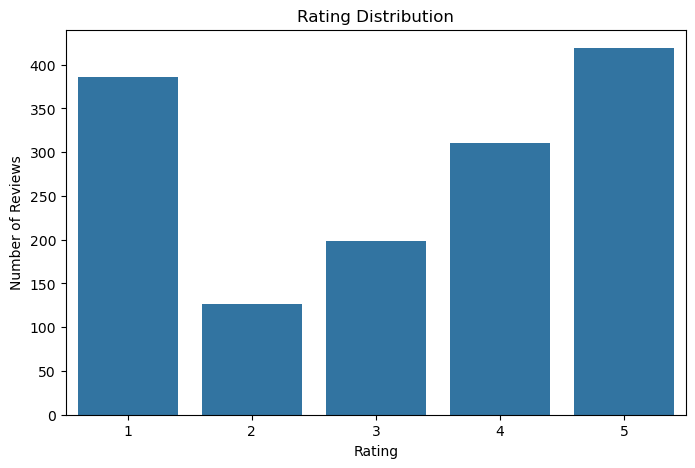

In [19]:
## Plot rating distribution..
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="rating")
plt.title("Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")

plt.show()

### Rating Distribution overview

In [20]:
## The rating distribution shows that all five rating categories are present in the dataset..
## The highest number of reviews are rated 5 stars with 419 reviews (29.10%) followed by 1 star reviews with 386 reviews (26.81%)..
## The lowest number of reviews are in the 2 star category with 126 reviews (8.75%)..

## The distribution is not completely balanced across the five rating categories..
## In particular the 2star category has considerably fewer reviews than the other ratings..
## This distribution will be important later when we create the sentiment labels and check the balance of the sentiment classes..

### Initial Text and Language/Data Quality Analysis

In [21]:
## Before creating sentiment labels or doing NLP preprocessing we should inspect whether the reviews contain English, Hindi, Hinglish/Romanized Hindi..
## or any other language patterns..
## Lets Display some random reviews..
# Display random customer reviews..

df[["title", "body", "rating"]].sample(20, random_state=42)

,title,body,rating
168,"Awesome phone, very long battery life, great feel",I am writing this review after 3 days of usage...,5
605,Phone is heavy and camera quality not good,Phone camera is not worth the quality mentione...,3
548,Phone is Extravagently cool and strong.,Everything is very good som people said proces...,5
65,It is USB 2.0 enabled device and not MHL compa...,I bought this phone mainly for my kids online ...,2
628,Worst product in case of Display quality.,Totally unsatisfied with the PLS TFT display a...,1
964,Great,"Good Delivery!Excellent Display, more wider an...",5
1390,Very Poor Response From Amazon,Camera quality is very poor as like VGA. Very ...,1
1422,Inbuilt apps lock not found,This product delivered by Amazon 21 march all...,4
1199,"Not for gamers, thumbs up for normal users","For normal user its quit good, but who wants t...",3
244,Monster 3 day battery,"Bought it for my mother, its a good phone with...",5


### Check for Hindi Script

In [22]:
## Check reviews containing Hindi/Devanagari characters..
hindi_script_reviews = df[df["body"].astype(str).str.contains(r"[\u0900-\u097F]", regex=True, na=False)]
print("Number of reviews containing Hindi/Devanagari characters:", len(hindi_script_reviews))

## Display a few examples..
hindi_script_reviews[["title", "body", "rating"]].head(10)

## This checks whether the review body contains characters from the Devanagari Unicode range which is used for Hindi..

Number of reviews containing Hindi/Devanagari characters: 12


,title,body,rating
7,कैसा दिखाते है उसका 10 % भी नही,मोबाइल का कैमरा बिल्कुल भी सही नही है 48 PM बत...,1
248,Damage product reshived,Damage product reshived hua hai or koi help na...,1
421,अमेज़न आपके द्वारा खरीदा samsung m12 6GB ram 12...,अमेज़न मेने आपके ऐप्प सेsamsung M126GB Ram 128 ...,1
460,असंतोषजनक,इस फोन में कई कमियां है जैसे इसकी नोटिफिकेशन ट...,1
524,पैसे की बर्बादी है ये मोबाइल,घण्टा true 48 megapixel कैमरा है !!!🔔🔔🔔🔔कैमरे ...,2
700,सैमसंग के मोबाइल के मेरे लिए बेस्ट रहते है।,ये सैमसंग का 5G का अच्छा मोबाइल है। मैं पहले स...,4
794,इस फोन में बहुत सारे प्रॉब्लम है,इस फोन में बहुत सारे प्रॉब्लम है चार्ज में लगा...,1
803,Samsung worst phone ever,"ना तो dual app work करता है, second whatsapp d...",1
887,"बकबास फ़ोन, पैसे खड्डे में गए","Worst phone. एक दम बकबास है, स्क्रीन शॉट सिस...",1
1051,कैमरा,इस mobile का कैमरा बहुत ही बकवास हैं कम्पनी द्...,1


### Check Possible Hinglish Reviews

In [23]:
## List of common Hindi/Hinglish words written in Roman/English script..
hinglish_words = [ "hai", "hain", "acha", "achha", "achhi", "achcha", "bahut", "bahot", "bekar", "bekaar", "badiya",
    "mast", "nahi", "nahin", "nhi", "mat", "kharab","paise", "paisa", "vasool", "bahut hi", "kaafi","sabse", "mera", "meri",
    "mere", "aap", "apka","kyu", "kyun", "kyuki", "lekin", "aur", "wala","wali", "bilkul", "sahi", "galat"]

## Create a pattern from the Hinglish words.
hinglish_pattern = r"\b(" + "|".join(hinglish_words) + r")\b"

## Find reviews containing possible Hinglish words..
possible_hinglish_reviews = df[df["body"].astype(str).str.lower().str.contains(hinglish_pattern, regex=True, na=False)]

print("Number of possible Hinglish reviews:", len(possible_hinglish_reviews))

## Display some possible Hinglish examples..
possible_hinglish_reviews[["title", "body", "rating"]].head(20)

Number of possible Hinglish reviews: 31


,title,body,rating
163,50-50 happy,Maine ye cell 17 ko order diya aur 19 ko mujhe...,4
248,Damage product reshived,Damage product reshived hua hai or koi help na...,1
258,Kam daam main bada dhamaka,This hand phone is perfect for those who want ...,5
302,good,after using the phone almost 4 months1. phone ...,3
340,Phone to achcha hai but….,"Phone to achcha hai. Main Sri lanka se, par In...",4
359,Mid range good quality.12 hajar ke andar acchi...,This is good product battery life is awesome i...,4
378,Don't but this Mobile,Please everyone attention don't but this Mobil...,1
394,Overlall Good Phone in This budget range agai...,"The Phone is Nice, Mai 3 din se use kr rha hun...",4
395,Mobile not good,Mobile lene k 15 din baad hi.. Uske loudspeake...,1
457,awesome phone thnaks amezone,i love samsung ab jab redme ke hi parige me sa...,5


In [24]:
## The dataset is mainly in English but it also contains some reviews written in Hindi script and some Hinglish/Romanized Hindi reviews..
## Therefore we should consider all three types during preprocessing and modeling rather than assuming that the complete dataset is English..

## But one important point: 31 is not necessarily the total number of Hinglish reviews in the dataset..
## Our keyword based method can only identify reviews containing the words in our selected list so some Hinglish reviews may not be detected..

### Create a language type column for analysis

In [25]:
## Before moving into preprocessing I recommend keeping all the reviews rather than removing the Hindi and Hinglish reviews..
## They are genuine customer feedback and removing them would unnecessarily reduce the available data..

## let's first create a simple language_type column for analysis purposes only:
## Hindi Script → Reviews containing Devanagari characters
## Possible Hinglish → Reviews matched by our Hinglish keyword check
## Other / Likely English → Remaining reviews

## We will call the remaining reviews Other / Likely English not simply English because we have not performed perfect language detection..

df["language_type"] = "Other / Likely English"

## Mark reviews containing Hindi/Devanagari script..
hindi_mask = df["body"].astype(str).str.contains(r"[\u0900-\u097F]", regex=True, na=False)

df.loc[hindi_mask, "language_type"] = "Hindi Script"

## Mark possible Hinglish reviews..
hinglish_mask = (df["body"].astype(str).str.lower().str.contains(hinglish_pattern, regex=True, na=False))

## Apply Hinglish only where the review is not already Hindi Script.
df.loc[hinglish_mask & ~hindi_mask, "language_type"] = "Possible Hinglish"

## Check language category counts..
language_counts = df["language_type"].value_counts()

print(language_counts)

## Check percentages..
language_percentages = (df["language_type"].value_counts(normalize=True) * 100).round(2)

print("\nLanguage category percentages:")
print(language_percentages)

language_type
Other / Likely English    1400
Possible Hinglish           28
Hindi Script                12
Name: count, dtype: int64

Language category percentages:
language_type
Other / Likely English    97.22
Possible Hinglish          1.94
Hindi Script               0.83
Name: proportion, dtype: float64


In [26]:
## 3 reviews matched both checks. Since our code gives Hindi Script priority, those 3 reviews are counted under Hindi Script.
## We should not treat Other / Likely English = 1400 as confirmed English and 28 as the total Hinglish reviews..
## These are only the categories produced by our current checks..
## Some Hinglish reviews may still be present in the Other / Likely English category..
## This indicates that the dataset is mainly composed of English-like reviews but it also contains Hindi and Hinglish content..

### Broader Possible Hinglish Detection

In [27]:
## Expanded Hinglish detection..

## Add only new Hinglish words to the existing list..
additional_hinglish_words = ["hu", "ho", "zabardast","na", "kyunki", "apna", "apne", "apko", "aapko","sab", "bahar", "andar",
    "liye", "liya", "karna","karo", "kiya", "karta","milta", "mila", "wale"]

## Combine the previous Hinglish words with the new additional words..
expanded_hinglish_words = hinglish_words + additional_hinglish_words

## Create a regex pattern using the expanded word list..
expanded_hinglish_pattern = (r"\b(" + "|".join(expanded_hinglish_words) + r")\b")

## Find reviews containing possible Hinglish words..
expanded_hinglish_reviews = df[df["body"].astype(str).str.lower().str.contains(expanded_hinglish_pattern, regex=True, na=False)]

## Display the number of possible Hinglish reviews detected..
print("Number of reviews identified as possible Hinglish:",len(expanded_hinglish_reviews))

## Display some examples for manual inspection..
expanded_hinglish_reviews[["title", "body", "rating"]].head(30)

Number of reviews identified as possible Hinglish: 34


,title,body,rating
163,50-50 happy,Maine ye cell 17 ko order diya aur 19 ko mujhe...,4
248,Damage product reshived,Damage product reshived hua hai or koi help na...,1
258,Kam daam main bada dhamaka,This hand phone is perfect for those who want ...,5
302,good,after using the phone almost 4 months1. phone ...,3
340,Phone to achcha hai but….,"Phone to achcha hai. Main Sri lanka se, par In...",4
359,Mid range good quality.12 hajar ke andar acchi...,This is good product battery life is awesome i...,4
378,Don't but this Mobile,Please everyone attention don't but this Mobil...,1
394,Overlall Good Phone in This budget range agai...,"The Phone is Nice, Mai 3 din se use kr rha hun...",4
395,Mobile not good,Mobile lene k 15 din baad hi.. Uske loudspeake...,1
457,awesome phone thnaks amezone,i love samsung ab jab redme ke hi parige me sa...,5


In [28]:
## Combine title and body for complete review text analysis..

df["combined_text"] = (df["title"].astype(str) + " " + df["body"].astype(str))

## Find possible Hinglish reviews using both title and body..
expanded_hinglish_mask = (df["combined_text"].str.lower().str.contains(expanded_hinglish_pattern, regex=True, na=False))

possible_hinglish_combined = df[expanded_hinglish_mask]

## Display the number of possible Hinglish reviews..
print("Number of possible Hinglish reviews found using title and body:", len(possible_hinglish_combined))

## Display some examples..
possible_hinglish_combined[["title", "body", "rating"]].head(30)

Number of possible Hinglish reviews found using title and body: 35


,title,body,rating
163,50-50 happy,Maine ye cell 17 ko order diya aur 19 ko mujhe...,4
248,Damage product reshived,Damage product reshived hua hai or koi help na...,1
258,Kam daam main bada dhamaka,This hand phone is perfect for those who want ...,5
300,Ok wala Phone,Built quality GoodBattery 🔋is Super GoodCamera...,3
302,good,after using the phone almost 4 months1. phone ...,3
340,Phone to achcha hai but….,"Phone to achcha hai. Main Sri lanka se, par In...",4
359,Mid range good quality.12 hajar ke andar acchi...,This is good product battery life is awesome i...,4
378,Don't but this Mobile,Please everyone attention don't but this Mobil...,1
394,Overlall Good Phone in This budget range agai...,"The Phone is Nice, Mai 3 din se use kr rha hun...",4
395,Mobile not good,Mobile lene k 15 din baad hi.. Uske loudspeake...,1


In [29]:
## 2 reviews contain Hindi/Devanagari script..
## 35 reviews were detected as possible Hinglish using our expanded keyword-based method on both title and body..
## The remaining reviews are categorized as Other / Likely English..

## However the 35 Hinglish reviews are not guaranteed to be the exact total
## because keyword-based detection can still miss some Hinglish reviews..

### Create Combined Review Text

In [30]:
## We will also use the combined title + body text as our main review text since sentiment information can exist in either column..

## Combine title and body into a single review text column..

df["review_text"] = (df["title"].astype(str).str.strip() + " " + df["body"].astype(str).str.strip())

## Display a few examples..
df[["title", "body", "review_text"]].head()

,title,body,review_text
0,Horrible product,Very disappointed with the overall performance...,Horrible product Very disappointed with the ov...
1,Camera quality is not like 48 megapixel,Camera quality is low,Camera quality is not like 48 megapixel Camera...
2,Overall,"Got the mobile on the launch date,Battery must...","Overall Got the mobile on the launch date,Batt..."
3,A big no from me,1. It doesn't work with 5.0GHz WiFi frequency....,A big no from me 1. It doesn't work with 5.0GH...
4,Put your money somewhere else,"Not worth buying....faulty software, poor disp...",Put your money somewhere else Not worth buying...


In [31]:
## Sentiment Label Creation..
## We currently have ratings from 1 to 5 but our machine learning model needs the target sentiment categories..

## For this project we will use:
## 1 and 2 → Negative
## 3 → Neutral
## 4 and 5 → Positive

## Create sentiment labels based on customer ratings..
def get_sentiment(rating):
    if rating <= 2:
        return "Negative"
    elif rating == 3:
        return "Neutral"
    else:
        return "Positive"


## Create the sentiment column..
df["sentiment"] = df["rating"].apply(get_sentiment)

## Display the first few rows..
df[["rating", "sentiment", "review_text"]].head()

,rating,sentiment,review_text
0,1,Negative,Horrible product Very disappointed with the ov...
1,3,Neutral,Camera quality is not like 48 megapixel Camera...
2,4,Positive,"Overall Got the mobile on the launch date,Batt..."
3,1,Negative,A big no from me 1. It doesn't work with 5.0GH...
4,1,Negative,Put your money somewhere else Not worth buying...


### Check the sentiment distribution

Sentiment Counts:
sentiment
Positive    729
Negative    512
Neutral     199
Name: count, dtype: int64

Sentiment Percentages:
sentiment
Positive    50.62
Negative    35.56
Neutral     13.82
Name: proportion, dtype: float64


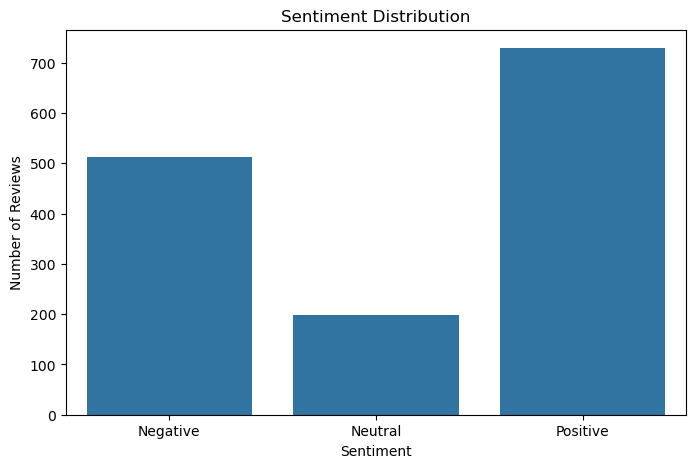

In [32]:
## Check sentiment counts..
sentiment_counts = df["sentiment"].value_counts()

print("Sentiment Counts:")
print(sentiment_counts)

## Check sentiment percentages..
sentiment_percentages = (df["sentiment"].value_counts(normalize=True) * 100).round(2)

print("\nSentiment Percentages:")
print(sentiment_percentages)

## Plot sentiment distribution..
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="sentiment", order=["Negative", "Neutral", "Positive"])
plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()

In [33]:
## The dataset contains 729 Positive reviews (50.62%), 512 Negative reviews (35.56%) and 199 Neutral reviews (13.82%)..
## Positive reviews form the largest class followed by Negative reviews while Neutral reviews are comparatively less represented..

## So the sentiment classes are not perfectly balanced especially because the Neutral class has fewer samples..
## We should keep this in mind later during the train-test split and model evaluation where metrics such as precision, recall and
## F1-score will be important instead of relying only on accuracy..

### Review Length Analysis

In [34]:
## Since we are using the combined review_text column let's calculate: Number of characters and Number of words..

## Calculate the number of characters in each review..
df["char_count"] = df["review_text"].apply(len)

## Calculate the number of words in each review..
df["word_count"] = df["review_text"].apply(lambda x: len(x.split()))

## Display basic statistics..
df[["char_count", "word_count"]].describe()

,char_count,word_count
count,1440.000000,1440.000000
mean,333.381944,58.257639
std,229.116704,39.896874
min,9.000000,2.000000
25%,198.000000,34.000000
50%,277.000000,49.000000
75%,395.000000,70.000000
max,2536.000000,391.000000


In [35]:
## The review length analysis shows that all 1440 reviews were included in the calculation..
## On average a review contains approximately 333 characters and 58 words..
## However the review lengths vary considerably as shown by the minimum and maximum values..
## The shortest review contains 9 characters and 2 words while the longest review contains 2536 characters and 391 words..
## The median review length is 277 characters and 49 words which means that half of the reviews contain fewer than 49 words and the other half contain more..

## The difference between the maximum values and the average values also shows that some reviews are much longer than others..

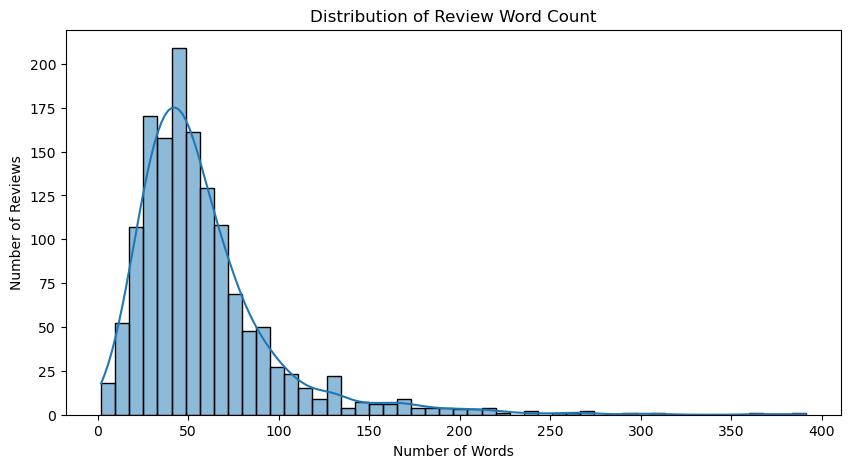

In [36]:
## Visualize the distribution of review word counts..
plt.figure(figsize=(10, 5))

sns.histplot(data=df, x="word_count", bins=50, kde=True)
plt.title("Distribution of Review Word Count")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")
plt.show()

In [37]:
## The distribution of review word counts is right-skewed,
## which means that most customer reviews contain a relatively smaller number of words while a few reviews are much longer..
## This is also consistent with our earlier statistics where the maximum word count of 391 is much higher than the median of 49 words..

### Review Length by Sentiment

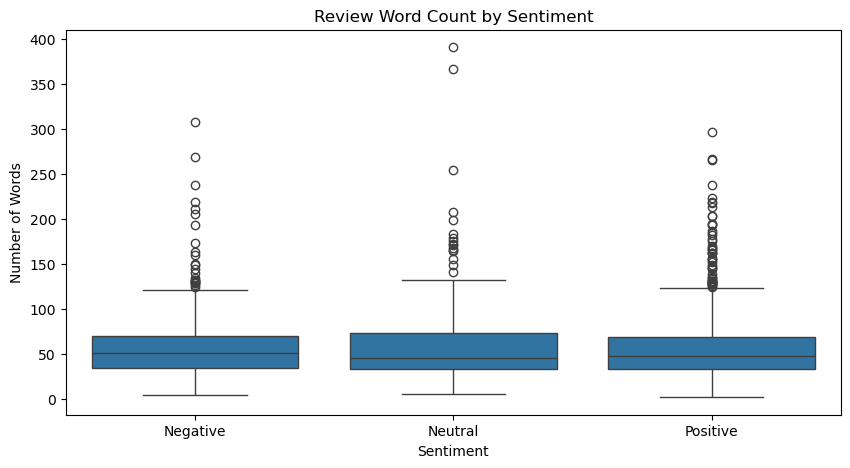

In [38]:
## Let's check whether Positive, Negative, and Neutral reviews tend to have different lengths..
## Compare review word counts across sentiment categories..
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="sentiment", y="word_count", order=["Negative", "Neutral", "Positive"])
plt.title("Review Word Count by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Number of Words")
plt.show()

In [39]:
## The boxplot shows that the review lengths are fairly similar across the Negative, Neutral and Positive sentiment categories as their median word counts and overall box ranges are relatively close..

## However there are several long review outliers in all three sentiment categories..
## The Neutral category contains the longest outliers, reaching close to 400 words while Negative and Positive reviews also contain some unusually long reviews..

## Overall review length does not appear to create a major difference between the sentiment categories based on this visualization..
## The main difference is the presence of some long reviews in each category..

### Text-Level EDA

In [40]:
## Lets analyzing the most frequently occurring words in the reviews..

## Before counting words we should create a basic cleaned version specifically for EDA..
## This is not our final NLP preprocessing. We are only preparing the text so that common words can be counted more meaningfully..

## Import required libraries for text processing..
import re
from collections import Counter

## Create a basic cleaned text column for text-level EDA..

def basic_text_cleaning(text):
    
    ## Convert text to lowercase..
    text = text.lower()
    
    ## Remove URLs..
    text = re.sub(r"http\S+|www\S+", "", text)
    
    ## Remove punctuation and special characters..
    text = re.sub(r"[^a-zA-Z\u0900-\u097F\s]", " ", text)
    
    ## Remove extra spaces..
    text = re.sub(r"\s+", " ", text).strip()
    
    return text


## Apply basic cleaning to the review text..
df["eda_clean_text"] = df["review_text"].apply(basic_text_cleaning)

## Display a few examples..
df[["review_text", "eda_clean_text"]].head()

,review_text,eda_clean_text
0,Horrible product Very disappointed with the ov...,horrible product very disappointed with the ov...
1,Camera quality is not like 48 megapixel Camera...,camera quality is not like megapixel camera qu...
2,"Overall Got the mobile on the launch date,Batt...",overall got the mobile on the launch date batt...
3,A big no from me 1. It doesn't work with 5.0GH...,a big no from me it doesn t work with ghz wifi...
4,Put your money somewhere else Not worth buying...,put your money somewhere else not worth buying...


### Top 20 most frequent words

In [41]:
## Combine all cleaned reviews into one text..
all_words = " ".join(df["eda_clean_text"]).split()

## Count word frequencies..
word_counts = Counter(all_words)

## Get the top 20 most frequent words..
top_20_words = word_counts.most_common(20)

## Convert the results into a DataFrame..
top_20_df = pd.DataFrame(top_20_words, columns=["Word", "Frequency"])
top_20_df

,Word,Frequency
0,is,3170
1,the,2293
2,phone,1881
3,and,1760
4,it,1618
5,this,1542
6,good,1479
7,for,1461
8,i,1452
9,not,1393


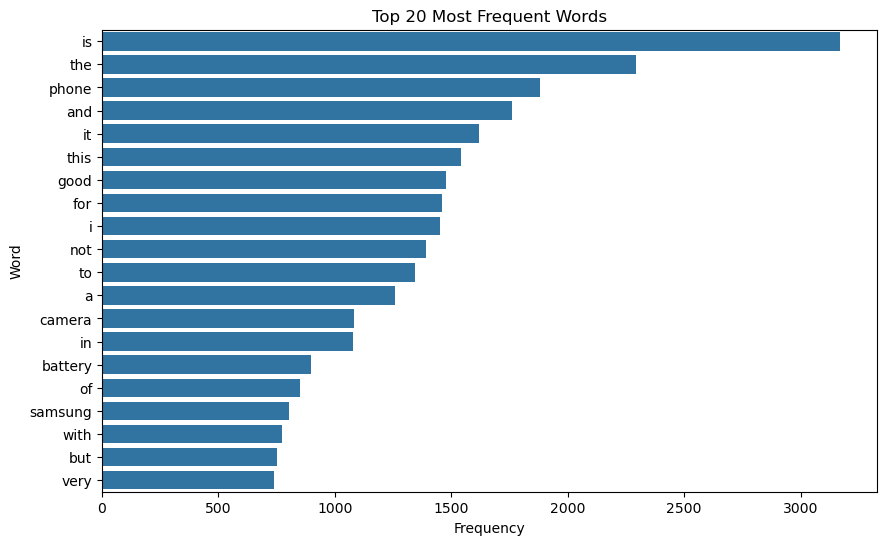

In [42]:
## Visualize the top 20 most frequent words..
plt.figure(figsize=(10, 6))
sns.barplot(data=top_20_df, x="Frequency", y="Word")
plt.title("Top 20 Most Frequent Words")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.show()

In [43]:
## The most frequent words include common words such as “is”, “the”, “and”, “it”, “this”, “for” and “to”..
## These words occur frequently but usually do not provide much useful information about the actual product or sentiment..
## On the other hand meaningful product related words such as “phone”, “camera”, “battery” and “samsung” appear frequently showing that customers commonly discuss these aspects of the product..

## Sentiment related words such as “good”, “not”, “but” and “very” are also among the most frequent words..
## In particular “not” is important because it can change the meaning of a sentiment phrase such as “not good”..
## This is something we need to keep in mind during final NLP preprocessing..

### Sentiment Wise Frequent Words

In [44]:
## Now let's check which words appear most frequently in each sentiment category..
## This can help us understand whether different sentiment classes contain different vocabulary..
## Function to get the top 20 most frequent words for each sentiment..

def get_top_words(sentiment_label, n=20):
    
    ## Combine all cleaned reviews for the selected sentiment..
    text = " ".join(df[df["sentiment"] == sentiment_label]["eda_clean_text"])
    
    ## Split the text into individual words..
    words = text.split()
    
    ## Count word frequencies..
    word_counts = Counter(words)
    
    ## Get the top n words..
    top_words = word_counts.most_common(n)
    
    ## Convert to DataFrame..
    top_words_df = pd.DataFrame(top_words, columns=["Word", "Frequency"])
    return top_words_df

## Get top 20 words for each sentiment..
positive_top_words = get_top_words("Positive")
negative_top_words = get_top_words("Negative")
neutral_top_words = get_top_words("Neutral")

## Display the results..
print("Top 20 Words in Positive Reviews")
display(positive_top_words)

print("\nTop 20 Words in Negative Reviews")
display(negative_top_words)

print("\nTop 20 Words in Neutral Reviews")
display(neutral_top_words)

Top 20 Words in Positive Reviews


,Word,Frequency
0,is,1741
1,the,1216
2,good,1076
3,phone,980
4,for,948
5,and,936
6,it,933
7,this,758
8,a,736
9,i,639



Top 20 Words in Negative Reviews


,Word,Frequency
0,is,949
1,the,732
2,phone,642
3,not,636
4,i,600
5,and,592
6,this,572
7,to,538
8,it,474
9,in,388



Top 20 Words in Neutral Reviews


,Word,Frequency
0,is,480
1,the,345
2,not,297
3,phone,259
4,and,232
5,to,217
6,good,213
7,i,213
8,this,212
9,it,211


In [45]:
## The frequent word analysis shows that some common words such as “is”, “the”, “and”, “this" and “it” appear across all three sentiment categories..
## These words are common in normal sentences and do not provide much sentiment specific information..

## In Positive reviews the word “good” appears frequently with 1,076 occurrences along with product related words such as “phone”,  “battery”, “camera”, “quality” and “price”..
## This suggests that positive reviews commonly discuss different aspects of the product while expressing positive opinions..

## In Negative reviews “not” appears 636 times making it one of the most frequent meaningful words..
## This supports our earlier point that negation words are important for sentiment analysis because phrases such as “not good” can express a completely different sentiment from the word “good” alone..
## Product-related words such as “phone”, “samsung”, “camera”, “quality” and “product” are also frequently discussed..

## In Neutral reviews the frequent words contain a mix of common words and product-related terms such as “phone”, “good”, “camera”, “quality”, “battery” and “mobile”..
## The word “not” also appears frequently showing that individual words alone may not always be enough to determine sentiment..
## The surrounding context will also be important..

## Overall this analysis supports our later decision to use N-grams, especially bigrams, 
## because phrases such as “not good” can provide more meaningful sentiment information than treating "not" and "good" completely separately..

### Visualize Sentiment-Wise Top Words

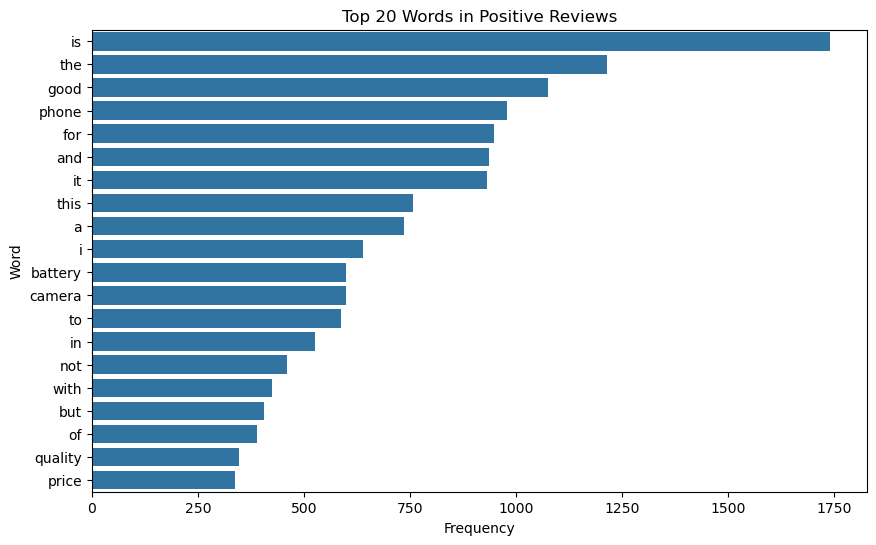

In [46]:
## Plot top 20 words in Positive reviews..
plt.figure(figsize=(10, 6))
sns.barplot(data=positive_top_words, x="Frequency", y="Word")
plt.title("Top 20 Words in Positive Reviews")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.show()

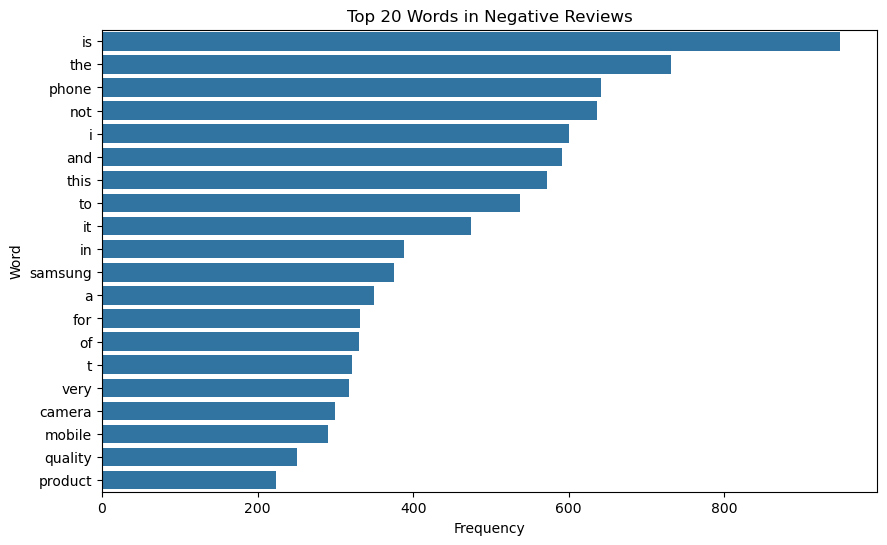

In [47]:
## Plot top 20 words in Negative reviews..
plt.figure(figsize=(10, 6))
sns.barplot(data=negative_top_words, x="Frequency", y="Word")
plt.title("Top 20 Words in Negative Reviews")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.show()

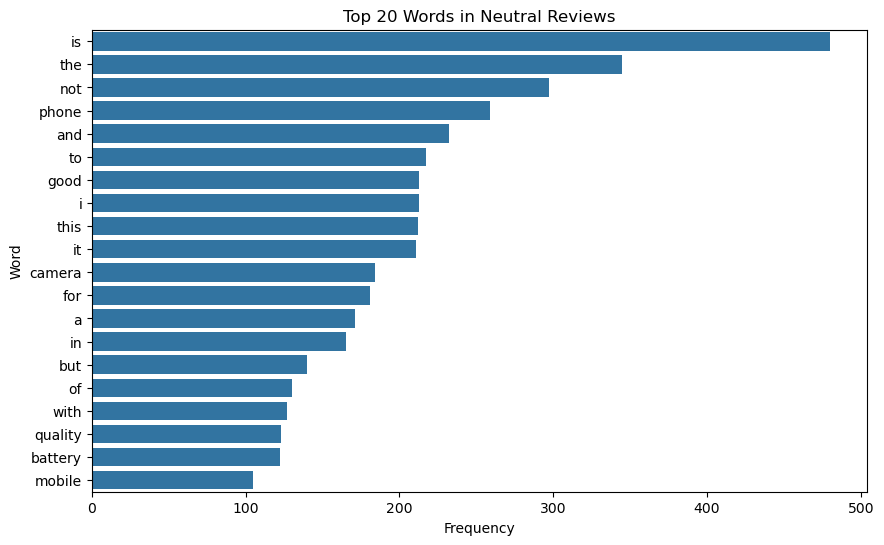

In [48]:
## Plot top 20 words in Neutral reviews..
plt.figure(figsize=(10, 6))
sns.barplot(data=neutral_top_words, x="Frequency", y="Word")
plt.title("Top 20 Words in Neutral Reviews")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.show()

### Word Clouds:

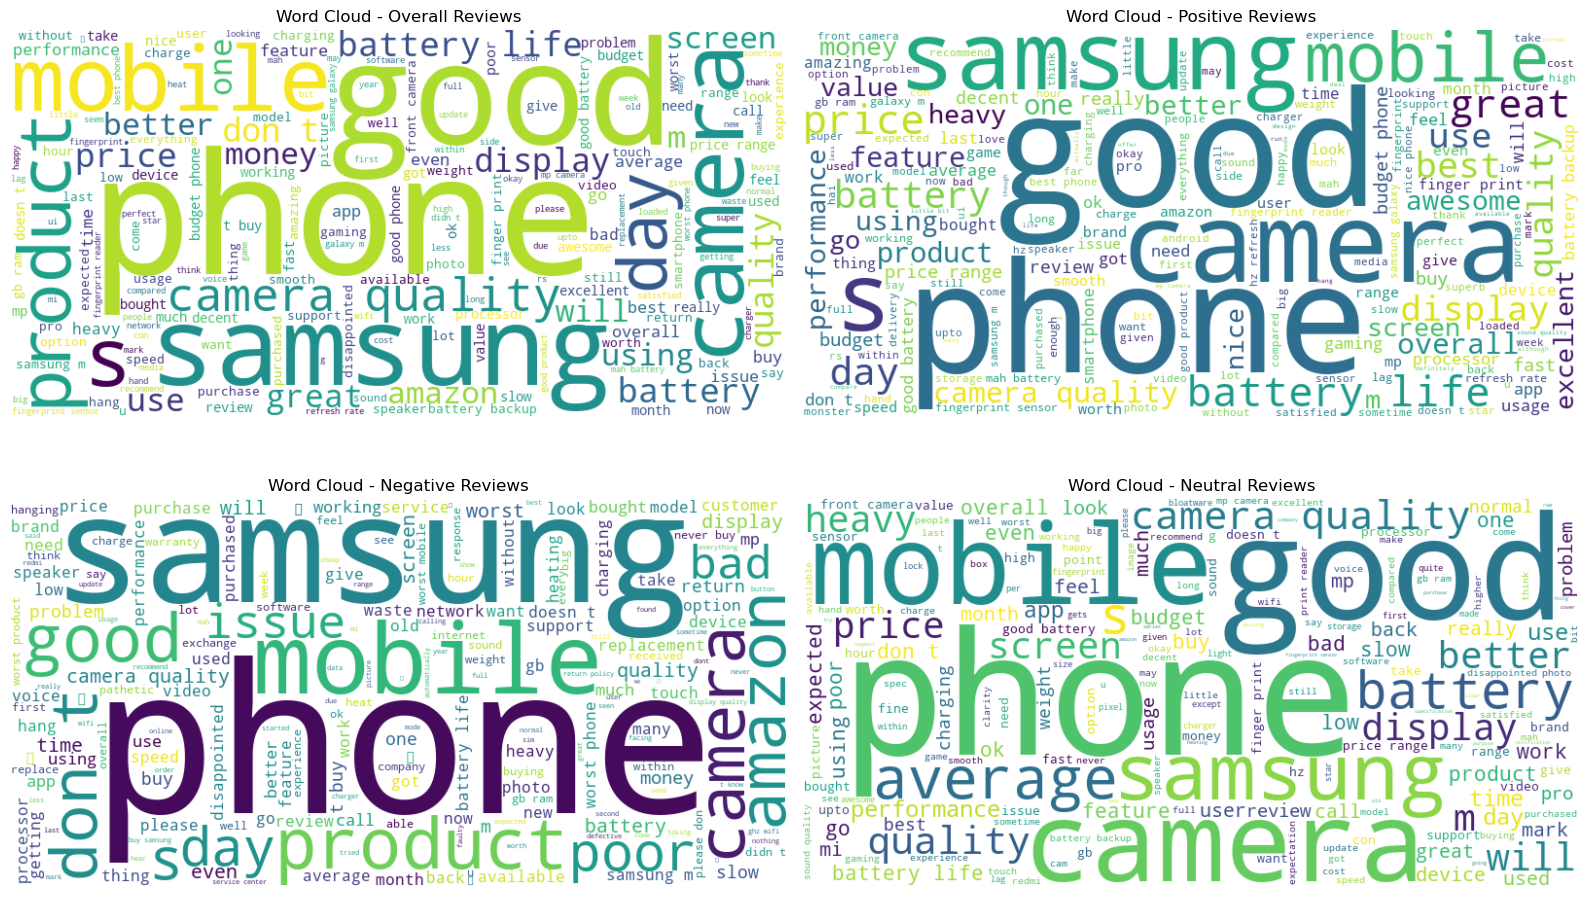

In [49]:
from wordcloud import WordCloud

## Create text for each category..
all_text = " ".join(df["eda_clean_text"])

positive_text = " ".join(df[df["sentiment"] == "Positive"]["eda_clean_text"])

negative_text = " ".join(df[df["sentiment"] == "Negative"]["eda_clean_text"])

neutral_text = " ".join(df[df["sentiment"] == "Neutral"]["eda_clean_text"])

## Create WordClouds..
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Overall WordCloud..
wordcloud_all = WordCloud(width=800, height=400, background_color="white").generate(all_text)
axes[0, 0].imshow(wordcloud_all, interpolation="bilinear")
axes[0, 0].set_title("Word Cloud - Overall Reviews")
axes[0, 0].axis("off")


## Positive WordCloud..
wordcloud_positive = WordCloud( width=800, height=400, background_color="white").generate(positive_text)
axes[0, 1].imshow(wordcloud_positive, interpolation="bilinear")
axes[0, 1].set_title("Word Cloud - Positive Reviews")
axes[0, 1].axis("off")


## Negative WordCloud..
wordcloud_negative = WordCloud(width=800, height=400, background_color="white").generate(negative_text)
axes[1, 0].imshow(wordcloud_negative, interpolation="bilinear")
axes[1, 0].set_title("Word Cloud - Negative Reviews")
axes[1, 0].axis("off")


## Neutral WordCloud..
wordcloud_neutral = WordCloud(width=800, height=400, background_color="white").generate(neutral_text)
axes[1, 1].imshow(wordcloud_neutral, interpolation="bilinear")
axes[1, 1].set_title("Word Cloud - Neutral Reviews")
axes[1, 1].axis("off")

plt.tight_layout()
plt.show()

## NLP Preprocessing

In [50]:
## Since eda_clean_text already contains the basic cleaning, we can continue from there without repeating those steps..
## First create a separate column from the EDA-cleaned text..
## This way, we keep eda_clean_text unchanged..

## Create a separate column for further NLP preprocessing..
df["processed_text"] = df["eda_clean_text"].copy()

## Display a few examples..
df[["eda_clean_text", "processed_text"]].head()

,eda_clean_text,processed_text
0,horrible product very disappointed with the ov...,horrible product very disappointed with the ov...
1,camera quality is not like megapixel camera qu...,camera quality is not like megapixel camera qu...
2,overall got the mobile on the launch date batt...,overall got the mobile on the launch date batt...
3,a big no from me it doesn t work with ghz wifi...,a big no from me it doesn t work with ghz wifi...
4,put your money somewhere else not worth buying...,put your money somewhere else not worth buying...


### Tokenization

In [51]:
## Now we will split each review into individual words..

## Import tokenizer..
from nltk.tokenize import word_tokenize

## Download the required NLTK resource..
import nltk
nltk.download("punkt")
nltk.download("punkt_tab")

## Tokenize the processed text.
df["tokens"] = df["processed_text"].apply(word_tokenize)

## Display original processed text and tokens
df[["processed_text", "tokens"]].head()

[nltk_data] Error loading punkt: HTTP Error 429: Too Many Requests
[nltk_data] Error loading punkt_tab: HTTP Error 429: Too Many Requests


,processed_text,tokens
0,horrible product very disappointed with the ov...,"[horrible, product, very, disappointed, with, ..."
1,camera quality is not like megapixel camera qu...,"[camera, quality, is, not, like, megapixel, ca..."
2,overall got the mobile on the launch date batt...,"[overall, got, the, mobile, on, the, launch, d..."
3,a big no from me it doesn t work with ghz wifi...,"[a, big, no, from, me, it, doesn, t, work, wit..."
4,put your money somewhere else not worth buying...,"[put, your, money, somewhere, else, not, worth..."


In [52]:
## we will handle stopwords carefully..

## Since this is a sentiment analysis project we should preserve negation words like "not", "no" and "never" 
## because removing them could change the meaning of phrases such as “not good”..

### Stopword Removal

In [ ]:
## Import stopwords..
from nltk.corpus import stopwords

## Download stopwords if not already downloaded..
nltk.download("stopwords")

## Load English stopwords..
stop_words = set(stopwords.words("english"))

## Define sentiment related words that should be preserved..
words_to_keep = {"not", "no", "nor", "never"}

## Remove these words from the stopword list..
stop_words = stop_words - words_to_keep


## Remove stopwords from tokenized text..
df["tokens_without_stopwords"] = df["tokens"].apply(lambda tokens: [word for word in tokens if word not in stop_words])

## Display the result..
df[["tokens", "tokens_without_stopwords"]].head()


## This step removes English stopwords only..
## Any Hindi or Hinglish words are not automatically removed by this English stopword list so they will remain in the text..

### Lemmatization

In [ ]:
## Now we will apply lemmatization to the tokens after stopword removal..

## Since our dataset contains some Hindi and Hinglish text, the English lemmatizer will mainly normalize English words..
## Hindi and Hinglish words that it does not recognize will generally remain unchanged..

## Import WordNetLemmatizer..
from nltk.stem import WordNetLemmatizer

## Download the required WordNet resources..
nltk.download("wordnet")
nltk.download("omw-1.4")

## Create a lemmatizer object..
lemmatizer = WordNetLemmatizer()

## Apply lemmatization to each token..
df["lemmatized_tokens"] = df["tokens_without_stopwords"].apply(lambda tokens: [lemmatizer.lemmatize(word)for word in tokens])

## Display the result..
df[[ "tokens_without_stopwords", "lemmatized_tokens" ]].head()

### Convert Tokens Back into Text

In [ ]:
## After lemmatization we need to join the tokens back into a sentence-like format because later, TF-IDF expects text input...

## Convert lemmatized tokens back into text..
df["final_processed_text"] = df["lemmatized_tokens"].apply(lambda tokens: " ".join(tokens))

## Compare original and final processed text..
df[[ "review_text",  "final_processed_text"]].head()

In [ ]:
## Before moving to Train-Test Split and TF-IDF, let's do one small final check on our processed text..
## This help us verify that the preprocessing has worked properly before using the text for modeling..
## Display original text and final processed text..

df[["review_text", "final_processed_text", "sentiment"]].sample(10, random_state=42)

### Prepare Features and Target

In [ ]:
## Define features and target variable..
X = df["final_processed_text"] ## Final processed review text..

y = df["sentiment"] ## Sentiment labels..

## Display shapes.
print("Feature shape:", X.shape)
print("Target shape:", y.shape)

### Train-Test Split

In [ ]:
## We will use: 80% training data, 20% testing data..random_state=42 for reproducibility..
## stratify=y to maintain the sentiment class distribution in both training and testing data..

## Import train_test_split..
from sklearn.model_selection import train_test_split

## Split the data into training and testing sets..
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

## Display the shapes..
print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

print("\nTraining target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

### Check Sentiment Distribution After Splitting

In [ ]:
## Since we used stratification, let's verify that the class proportions are maintained..

## Check sentiment distribution in training data..
print("Training Data Sentiment Distribution:")
print(y_train.value_counts())

print("\nTraining Data Sentiment Percentages:")
print((y_train.value_counts(normalize=True) * 100).round(2))


## Check sentiment distribution in testing data..
print("\nTesting Data Sentiment Distribution:")
print(y_test.value_counts())

print("\nTesting Data Sentiment Percentages:")
print((y_test.value_counts(normalize=True) * 100).round(2))

In [ ]:
## The sentiment proportions are almost the same across the original, training and testing datasets..
## This confirms that using stratify=y successfully maintained the class distribution during the train-test split..
## Therefore both datasets contain a representative proportion of Positive, Negative and Neutral reviews..

## TF-IDF Text Representation

In [ ]:
## we will move to TF-IDF and make sure we fit the vectorizer only on X_train, not on the complete dataset to avoid data leakage..
## we will use TF-IDF with unigrams and bigrams..

### Create and Fit the TF-IDF Vectorizer

In [ ]:
## Import TF-IDF Vectorizer..
from sklearn.feature_extraction.text import TfidfVectorizer

## Create the TF-IDF vectorizer..
tfidf_vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))

## Fit the vectorizer only on the training data..
## and transform the training text..
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)

## Transform the testing data using the same fitted vectorizer..
X_test_tfidf = tfidf_vectorizer.transform(X_test)

## Display the shapes..
print("Training TF-IDF Shape:", X_train_tfidf.shape)
print("Testing TF-IDF Shape:", X_test_tfidf.shape)

In [ ]:
## The training dataset contains 1152 reviews including 583 Positive (50.61%), 410 Negative (35.59%) and 159 Neutral (13.80%) reviews..
## The distribution is very close to the original dataset's sentiment distribution..

## The testing dataset contains 288 reviews including 146 Positive (50.69%), 102 Negative (35.42%) and 40 Neutral (13.89%) reviews..
## This distribution is also very similar to both the original dataset and training dataset..

## The TF-IDF transformation produced 5000 features for both datasets..
## The training data has a shape of (1152, 5000) meaning 1,152 training reviews are represented using 5000 TF-IDF features..
## Similarly the testing data has a shape of (288, 5000)..

In [ ]:
## ngram_range=(1, 2) allows the model to learn both..
## Unigrams: good, camera, battery..
## Bigrams: not good, very good, etc..

### Check Some TF-IDF Features

In [ ]:
## Display some words and phrases from the TF-IDF vocabulary..
feature_names = tfidf_vectorizer.get_feature_names_out()

print("Total Number of TF-IDF Features:", len(feature_names))

print("\nSample TF-IDF Features:")
print(feature_names[:50])

In [ ]:
## The TF-IDF vectorizer successfully created 5000 features which is the maximum number specified using max_features=5000..
## The sample features contain both individual words (unigrams) such as aap, achcha, camera and affordable..
## as well as two-word combinations (bigrams) such as able hear, according price, adaptive brightness and affordable price..

## The presence of words like aap and achcha also shows that Hinglish words were retained during preprocessing and included in the TF-IDF vocabulary..
## This means our text representation is able to preserve vocabulary from the mixed-language reviews instead of using only English words..

## Baseline Model

### Multinomial Naive Bayes

In [ ]:
## we can start model building..
## Since this is a text classification problem, let's first build a baseline model using Multinomial Naive Bayes..

## Import Multinomial Naive Bayes..
from sklearn.naive_bayes import MultinomialNB

## Create the baseline model..
nb_model = MultinomialNB()

## Train the model using the TF-IDF training data..
nb_model.fit(X_train_tfidf, y_train)

## Make predictions on the testing data..
y_pred_nb = nb_model.predict(X_test_tfidf)

#### Evaluate the Baseline Model

In [ ]:
## Import evaluation metrics..
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix)

## Calculate accuracy..
nb_accuracy = accuracy_score(y_test, y_pred_nb)
print("Naive Bayes Accuracy:", round(nb_accuracy * 100, 2), "%")

## Display classification report..
print("\nClassification Report:\n")
print(classification_report( y_test, y_pred_nb))

#### Confusion Matrix

In [ ]:
## Display confusion matrix..
cm_nb = confusion_matrix(y_test, y_pred_nb, labels=["Negative", "Neutral", "Positive"])
plt.figure(figsize=(7, 5))
sns.heatmap(cm_nb, annot=True, fmt="d", xticklabels=["Negative", "Neutral", "Positive"], yticklabels=["Negative", "Neutral", "Positive"])
plt.title("Confusion Matrix - Multinomial Naive Bayes")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.show()

In [ ]:
## The Multinomial Naive Bayes baseline model achieved an overall accuracy of 76.74%..
## However accuracy alone does not show the complete performance because the dataset contains three sentiment classes with different numbers of samples..

## The model performed reasonably well for the Negative class with an F1-score of 0.79 and 
## performed best for the Positive class with an F1-score of 0.84..
## The Positive class has a very high recall of 0.99 which means the model was able to identify almost all actual Positive reviews..

## However the major problem is the Neutral class where precision, recall and F1-score are all 0.00..
## This means the model was unable to correctly identify any Neutral reviews..
## Therefore even though the overall accuracy is around 77% the model is not performing well across all sentiment categories..

## The macro average F1-score of 0.55 also reflects this uneven performance because it gives equal importance to all three classes..
## Therefore this model will be treated as our baseline and we should experiment with other models to improve the overall performance especially for the Neutral class..

### Logistic Regression model

In [ ]:
## Import Logistic Regression..
from sklearn.linear_model import LogisticRegression

## Create the model..
lr_model = LogisticRegression(max_iter=1000, random_state=42)

## Train the model..
lr_model.fit(X_train_tfidf, y_train)

## Make predictions on the testing data..
y_pred_lr = lr_model.predict(X_test_tfidf)

#### Evaluate Logistic Regression

In [ ]:
## Calculate accuracy..
lr_accuracy = accuracy_score(y_test, y_pred_lr)
print("Logistic Regression Accuracy:", round(lr_accuracy * 100, 2), "%")

## Display classification report..
print("\nClassification Report:\n")
print(classification_report( y_test, y_pred_lr))

#### Confusion Matrix

In [ ]:
## Create confusion matrix..
cm_lr = confusion_matrix(y_test, y_pred_lr, labels=["Negative", "Neutral", "Positive"])

## Plot confusion matrix..
plt.figure(figsize=(7, 5))
sns.heatmap(cm_lr, annot=True, fmt="d", xticklabels=["Negative", "Neutral", "Positive"], yticklabels=["Negative", "Neutral", "Positive"])
plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.show()

In [ ]:
## The Logistic Regression model achieved an accuracy of 78.12% which is slightly better than the Naive Bayes baseline accuracy of 76.74%..

## The model performed well for both the Negative and Positive classes..
## The Negative class achieved an F1-score of 0.82 while the Positive class achieved the highest F1-score of 0.86..

## For the Neutral class the model performed better than Naive Bayes because it was able to correctly identify some Neutral reviews.. 
## However its performance is still weak with an F1-score of 0.09 and a recall of only 0.05..
## This means that the model is still struggling to identify Neutral reviews correctly..

## Overall Logistic Regression performs slightly better than the baseline model..
## Its macro average F1-score improved from 0.55 to 0.59 and its weighted average F1-score improved from 0.71 to 0.74..
## However there is still significant room for improvement especially for the Neutral sentiment class..

### Linear Support Vector Machine (Linear SVC)

In [ ]:
## Import Linear SVC..
from sklearn.svm import LinearSVC

## Create the model..
svm_model = LinearSVC(random_state=42)

## Train the model..
svm_model.fit(X_train_tfidf, y_train)

## Make predictions on the testing data..
y_pred_svm = svm_model.predict(X_test_tfidf)

#### Evaluate Linear SVM

In [ ]:
## Calculate accuracy..
svm_accuracy = accuracy_score(y_test, y_pred_svm)
print("Linear SVM Accuracy:", round(svm_accuracy * 100, 2), "%")

## Display classification report..
print("\nClassification Report:\n")
print(classification_report( y_test, y_pred_svm))

#### Confusion Matrix

In [ ]:
## Create confusion matrix..
cm_svm = confusion_matrix(y_test, y_pred_svm, labels=["Negative", "Neutral", "Positive"])

## Plot confusion matrix..
plt.figure(figsize=(7, 5))
sns.heatmap(cm_svm, annot=True, fmt="d", xticklabels=["Negative", "Neutral", "Positive"], yticklabels=["Negative", "Neutral", "Positive"])
plt.title("Confusion Matrix - Linear SVM")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.show()

In [ ]:
## The Linear SVM model achieved an accuracy of 78.47% which is the highest accuracy among the three models tested so far..

## The model performed well for the Positive class with an F1-score of 0.88 and reasonably well for the Negative class, with an F1-score of 0.79..

## The most important improvement is in the Neutral class..
## Linear SVM achieved an F1-score of 0.25 and a recall of 0.17 which is better than both Naive Bayes and Logistic Regression..
## However Neutral sentiment is still the most difficult class for the model to identify..

## The macro average F1-score is 0.64 which is also higher than Naive Bayes: 0.55, Logistic Regression: 0.59
## Similarly the weighted average F1-score of 0.76 is the best among the models tested so far..

## So currently Linear SVM is our best-performing model, especially when considering not just accuracy but also the overall performance across all three sentiment classes..

### Random Forest Classifier

In [ ]:
## Import Random Forest Classifier..
from sklearn.ensemble import RandomForestClassifier

## Create the model..
rf_model = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)

## Train the model..
rf_model.fit(X_train_tfidf, y_train)

## Make predictions on the testing data..
y_pred_rf = rf_model.predict(X_test_tfidf)

#### Evaluate Random Forest

In [ ]:
## Calculate accuracy..
rf_accuracy = accuracy_score(y_test, y_pred_rf)
print("Random Forest Accuracy:", round(rf_accuracy * 100, 2), "%")

## Display classification report..
print("\nClassification Report:\n")
print(classification_report( y_test, y_pred_rf))

#### Confusion Matrix

In [ ]:
## Create confusion matrix..
cm_rf = confusion_matrix(y_test, y_pred_rf, labels=["Negative", "Neutral", "Positive"])

## Plot confusion matrix..
plt.figure(figsize=(7, 5))
sns.heatmap(cm_rf, annot=True, fmt="d", xticklabels=["Negative", "Neutral", "Positive"], yticklabels=["Negative", "Neutral", "Positive"])
plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.show()

In [ ]:
## The Random Forest model achieved an accuracy of 77.43% which is lower than the Linear SVM accuracy of 78.47% but slightly higher than the Naive Bayes baseline accuracy of 76.74%..

## The model performed reasonably well for the Negative class with an F1-score of 0.79 and 
## performed well for the Positive class, with an F1-score of 0.85..

## However the model performed very poorly for the Neutral class..
## Although it achieved a precision of 1.00, its recall was only 0.03, with an F1-score of 0.05..
## This means the model predicted very few reviews as Neutral and therefore failed to identify most of the actual Neutral reviews..

## The macro average F1-score of 0.57 is lower than Logistic Regression (0.59) and Linear SVM (0.64)..
## Similarly the weighted average F1-score of 0.72 is also lower than Linear SVM's 0.76..

## Overall Random Forest performs reasonably well for Positive and Negative reviews but struggles significantly with the Neutral class.. 
## Therefore Linear SVM remains the best-performing model among the four models tested so far, considering accuracy as well as the overall balance of performance across all three sentiment classes..

In [ ]:
## Store model performance metrics..
model_results = pd.DataFrame({"Model": ["Multinomial Naive Bayes", "Logistic Regression", "Linear SVM", "Random Forest"],
    "Accuracy (%)": [76.74, 78.12, 78.47, 77.43], "Macro F1-Score": [0.55, 0.59, 0.64, 0.57],
    "Weighted F1-Score": [0.71, 0.74, 0.76, 0.72 ]})

## Display the results by sorting them by accuracy in decendending order.. 
model_results = model_results.sort_values(by="Accuracy (%)", ascending=False).reset_index(drop=True)
model_results

In [ ]:
## Among the four models tested Linear SVM is currently the best-performing model..
## It achieved the highest accuracy of 78.47% along with the highest Macro F1-score (0.64) and Weighted F1-score (0.76)..

## More importantly Linear SVM performed better than the other models in identifying the Neutral class, although Neutral sentiment is still difficult to classify..
## Therefore based on the current results, Linear SVM should be selected as our current best model..

In [ ]:
## We should not directly finalize the Linear SVM yet..
## Since the Neutral class is still weak, the next logical step is to try improving the best model..

## We will first perform hyperparameter tuning for Linear SVM using GridSearchCV..

### Hyperparameter Tuning for Linear SVM

In [ ]:
## Import GridSearchCV..
from sklearn.model_selection import GridSearchCV

## Define the parameter values to test..
param_grid = {"C": [0.01, 0.1, 1, 10, 100]}

## Create a new Linear SVM model..
svm_grid_model = LinearSVC(random_state=42)

## Create GridSearchCV..
grid_search = GridSearchCV(estimator=svm_grid_model, param_grid=param_grid, cv=5, scoring="f1_macro", n_jobs=-1)

## Train GridSearchCV on the training data..
grid_search.fit(X_train_tfidf, y_train)

## Display the best parameter..
print("Best Parameters:")
print(grid_search.best_params_)

## Display the best cross-validation score..
print("\nBest Cross-Validation Macro F1-Score:")
print(round(grid_search.best_score_, 4))

In [ ]:
## We used f1_macro as the scoring metric because accuracy alone can hide poor performance on the smaller Neutral class..
## Macro F1 gives equal importance to Negative, Neutral, and Positive..

## C = 1 is the best parameter value among the values we tested..
## The best 5-fold cross-validation Macro F1-score is 0.6503, which means the model achieved an average Macro F1-score of around 0.65 during cross-validation..
## Since Macro F1 gives equal importance to all three sentiment classes, this is a useful metric for our dataset, especially because the Neutral class has fewer samples..

#### Evaluate Tuned Linear SVM

In [ ]:
## Let's evaluate the best tuned Linear SVM model on the test data..
## Let's get the best Linear SVM model from GridSearchCV..
best_svm_model = grid_search.best_estimator_

## Make predictions on the testing data..
y_pred_best_svm = best_svm_model.predict(X_test_tfidf)

#### Accuracy and Classification Report

In [ ]:
## Calculate accuracy..
best_svm_accuracy = accuracy_score(y_test, y_pred_best_svm)
print("Tuned Linear SVM Accuracy:", round(best_svm_accuracy * 100, 2), "%")

## Display classification report..
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_best_svm))

#### Confusion Matrix

In [ ]:
## Create confusion matrix..
cm_best_svm = confusion_matrix(y_test, y_pred_best_svm, labels=["Negative", "Neutral", "Positive"])

## Plot confusion matrix.
plt.figure(figsize=(7, 5))
sns.heatmap(cm_best_svm, annot=True, fmt="d", xticklabels=["Negative", "Neutral", "Positive"], yticklabels=["Negative", "Neutral", "Positive"])
plt.title("Confusion Matrix - Tuned Linear SVM")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.show()

In [ ]:
## The tuned Linear SVM achieved an accuracy of 78.47% which is the same as the original Linear SVM..
## The precision, recall and F1-scores for all three sentiment classes are also unchanged..

## This happened because the best value found during GridSearchCV was C = 1, which is already the default value used by our original LinearSVC model..
## Therefore hyperparameter tuning did not change the model configuration or improve its test performance..

## The cross-validation Macro F1-score was 0.6503, while the test Macro F1-score remained 0.64..
## This shows that the model performance is reasonably consistent between cross-validation and the test dataset..

## Therefore we can conclude that hyperparameter tuning did not improve the Linear SVM model and the original Linear SVM with C=1 remains our best model..

### Save the model and vectorizer

In [ ]:
## Let's save both the trained Linear SVM model and the TF-IDF vectorizer..
## Import joblib..
import joblib

## Save the final Linear SVM model..
joblib.dump(svm_model, "linear_svm_sentiment_model.pkl")

## Save the fitted TF-IDF vectorizer..
joblib.dump(tfidf_vectorizer, "tfidf_vectorizer.pkl")
print("Model and TF-IDF vectorizer saved successfully.")

### Final model comparison table including the Tuned Linear SVM

In [ ]:
## Create final model comparison table..
final_model_results = pd.DataFrame({"Model": ["Multinomial Naive Bayes", "Logistic Regression", "Linear SVM", "Random Forest", "Tuned Linear SVM"], 
                                    "Accuracy (%)": [76.74, 78.12, 78.47, 77.43, 78.47], "Macro F1-Score": [0.55, 0.59, 0.64, 0.57, 0.64],
                                    "Weighted F1-Score": [0.71, 0.74, 0.76, 0.72, 0.76 ]})

## Sort by Accuracy and Macro F1-Score..
final_model_results = final_model_results.sort_values(by=["Accuracy (%)", "Macro F1-Score"], ascending=False).reset_index(drop=True)
final_model_results

In [ ]:
## Among all the models tested, Linear SVM achieved the best overall performance with an accuracy of 78.47%, a Macro F1-score of 0.64
## and a Weighted F1-score of 0.76..
## Hyperparameter tuning was also performed using GridSearchCV but the best value found was C = 1,
## which is the default parameter already used in the original Linear SVM model..
## As a result the Tuned Linear SVM produced exactly the same test performance and did not provide any additional improvement..

## Therefore the original Linear SVM model is selected as the final model for this sentiment analysis project..

### Final Model Testing on Custom Reviews

In [ ]:
## Create sample custom reviews in English, Hinglish and Hindi.. 

custom_reviews = [## English - Positive
    "This phone is very good and the camera quality is excellent",
    ## English - Negative
    "Worst product, battery is very bad and not working properly",
    ## English - Neutral
    "Phone is okay but the camera could be better",
    ## Hinglish - Positive
    "Ye phone bahut acha hai aur camera bhi mast hai",
    ## Hinglish - Negative
    "Bahut bekar product hai, paise waste ho gaye",
     ## Hindi - Positive
    "यह फोन बहुत अच्छा है और इसका कैमरा भी बहुत बढ़िया है",
    ## Hindi - Negative
    "यह बहुत खराब फोन है और बैटरी बिल्कुल अच्छी नहीं है",
    ## Hindi - Neutral
    "फोन ठीक है लेकिन कैमरा और बेहतर हो सकता था"]


## Apply the same preprocessing used during training.. 
def preprocess_custom_text(text):
    
    text = text.lower() ## Convert text to lowercase..
    
    text = re.sub(r"http\S+|www\S+", "", text) ## Remove URLs..
    
    text = re.sub(r"[^a-zA-Z\u0900-\u097F\s]", " ", text) ## Remove unwanted characters while keeping Hindi script..
    
    text = re.sub(r"\s+", " ", text).strip() ## Remove extra spaces..
    
    tokens = word_tokenize(text) ## Tokenize..
    
    tokens = [word for word in tokens if word not in stop_words ] ## Remove English stopwords..
    
    tokens = [lemmatizer.lemmatize(word) for word in tokens] ## Apply lemmatization..
    
    return " ".join(tokens) ## Convert tokens back into text..


## Preprocess the custom reviews..
processed_custom_reviews = [preprocess_custom_text(review) for review in custom_reviews]


## Convert the reviews into TF-IDF features..
custom_reviews_tfidf = tfidf_vectorizer.transform(processed_custom_reviews)


## Predict sentiment using the final Linear SVM model..
custom_predictions = svm_model.predict( custom_reviews_tfidf)


## Display the results..
custom_results = pd.DataFrame({ "Review": custom_reviews, "Predicted Sentiment": custom_predictions})
custom_results

### Model Experiment — Balanced Linear SVM

In [ ]:
## Create a Linear SVM with balanced class weights..
balanced_svm_model = LinearSVC(class_weight="balanced", random_state=42)

## Train the model..
balanced_svm_model.fit(X_train_tfidf, y_train)

## Make predictions..
y_pred_balanced_svm = balanced_svm_model.predict(X_test_tfidf)

#### Evaluate it

In [ ]:
## Calculate accuracy..
balanced_svm_accuracy = accuracy_score(y_test, y_pred_balanced_svm)
print("Balanced Linear SVM Accuracy:", round(balanced_svm_accuracy * 100, 2), "%")

## Display classification report..
print("\nClassification Report:\n")
print(classification_report( y_test, y_pred_balanced_svm))

In [ ]:
## The Balanced Linear SVM achieved an accuracy of 78.12% which is slightly lower than the original Linear SVM accuracy of 78.47%..
## However the main purpose of using class weights was to improve the performance of the Neutral class and we can see some improvement there..
## The Neutral recall increased from 0.17 to 0.23 and the Neutral F1-score improved from 0.25 to 0.28..
## The overall Macro F1-score also increased from 0.64 to 0.65 while the Weighted F1-score increased from 0.76 to 0.77..
## So although the accuracy decreased slightly by 0.35%, the model achieved a more balanced performance across all three sentiment classes..
## Therefore class_weight="balanced" did provide some improvement especially for the Neutral class but the improvement is still relatively small..
## The Neutral class remains the main challenge..

In [ ]:
## So far our experiments are:

## 1) Original Linear SVM + TF-IDF (1,2) → Accuracy 78.47%, Neutral F1 0.25
## 2) Balanced Linear SVM + TF-IDF (1,2) → Accuracy 78.12%, Neutral F1 0.28

In [ ]:
## We will now test->

## TF-IDF with Unigrams + Bigrams + Trigrams (1,3) + normal Linear SVM..
## Then we can check whether adding trigrams improves the Neutral class..
## After that if the results look promising we can also test: TF-IDF (1,3) + Balanced Linear SVM..
## That will allow us to compare the effect of both trigrams and class balancing separately and together..

### Model Experiment — TF-IDF with Unigrams, Bigrams, and Trigrams

In [ ]:
## Now We will create a new TF-IDF vectorizer with ngram_range=(1, 3)..
## We will keep it separate from the previous TF-IDF vectorizer so we can compare the experiments properly..

## Create a new TF-IDF vectorizer..
## Using unigrams, bigrams, and trigrams..
tfidf_vectorizer_13 = TfidfVectorizer(max_features=5000, ngram_range=(1, 3))

## Fit only on the training data..
X_train_tfidf_13 = tfidf_vectorizer_13.fit_transform(X_train)

## Transform the testing data using the same vectorizer..
X_test_tfidf_13 = tfidf_vectorizer_13.transform(X_test)

## Display the shapes..
print("Training TF-IDF Shape:", X_train_tfidf_13.shape)
print("Testing TF-IDF Shape:", X_test_tfidf_13.shape)

In [ ]:
## Now let's train a normal Linear SVM using these new TF-IDF features..
## Create Linear SVM model..
svm_trigram_model = LinearSVC(random_state=42)

## Train the model using TF-IDF (1,3)..
svm_trigram_model.fit(X_train_tfidf_13,  y_train)

## Make predictions..
y_pred_svm_trigram = svm_trigram_model.predict(X_test_tfidf_13)

#### Evaluate the Model

In [ ]:
## Calculate accuracy..
svm_trigram_accuracy = accuracy_score(y_test, y_pred_svm_trigram)
print("Linear SVM with TF-IDF (1,3) Accuracy:", round(svm_trigram_accuracy * 100, 2), "%")

## Display classification report..
print("\nClassification Report:\n")
print(classification_report( y_test, y_pred_svm_trigram))

#### Confusion matrix

In [ ]:
## Create confusion matrix..
cm_svm_trigram = confusion_matrix(y_test, y_pred_svm_trigram, labels=["Negative", "Neutral", "Positive"])

## Plot confusion matrix..
plt.figure(figsize=(7, 5))
sns.heatmap(cm_svm_trigram, annot=True, fmt="d", xticklabels=["Negative", "Neutral", "Positive"], yticklabels=["Negative", "Neutral", "Positive"])
plt.title("Confusion Matrix - Linear SVM with TF-IDF (1,3)")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.show()

In [ ]:
## The Linear SVM model using unigrams, bigrams and trigrams achieved an accuracy of 78.47% 
## which is exactly the same as the original Linear SVM using TF-IDF (1,2)..
## However adding trigrams did not improve the Neutral class..
## The Neutral F1-score decreased from 0.25 to 0.22 and recall decreased from 0.17 to 0.15..
## The Macro F1-score also decreased slightly from 0.64 to 0.63..
## The Positive and Negative classes continued to perform well but the additional trigram features did not provide any meaningful improvement..

## Idea of testing trigrams was absolutely reasonable but based on our actual results,
## TF-IDF (1,3) does not perform better than (1,2) for this dataset..

## Class weighting improved Neutral performance more than adding trigrams..

| Model / Experiment            |   Accuracy | Neutral F1 | Macro F1 |
| ----------------------------- | ---------: | ---------: | -------: |
| Original SVM + TF-IDF `(1,2)` | **78.47%** |       0.25 |     0.64 |
| Balanced SVM + TF-IDF `(1,2)` |     78.12% |   **0.28** | **0.65** |
| SVM + TF-IDF `(1,3)`          | **78.47%** |       0.22 |     0.63 |

### Model Experiment — TF-IDF (1,3) + Linear SVM with class_weight="balanced"

In [ ]:
## Now we will test the combined approach..
## Create Balanced Linear SVM model..
balanced_svm_trigram_model = LinearSVC(class_weight="balanced", random_state=42)

## Train the model using TF-IDF (1,3)..
balanced_svm_trigram_model.fit(X_train_tfidf_13, y_train)

## Make predictions on the testing data..
y_pred_balanced_svm_trigram = balanced_svm_trigram_model.predict(X_test_tfidf_13)

#### Evaluation

In [ ]:
## Calculate accuracy..
balanced_svm_trigram_accuracy = accuracy_score(y_test, y_pred_balanced_svm_trigram)
print("Balanced Linear SVM with TF-IDF (1,3) Accuracy:", round(balanced_svm_trigram_accuracy * 100, 2), "%")

## Display classification report..
print("\nClassification Report:\n")
print(classification_report( y_test, y_pred_balanced_svm_trigram))

#### Confusion Matrix

In [ ]:
## Create confusion matrix..
cm_balanced_svm_trigram = confusion_matrix(y_test, y_pred_balanced_svm_trigram, labels=["Negative", "Neutral", "Positive"])

## Plot confusion matrix..
plt.figure(figsize=(7, 5))
sns.heatmap(cm_balanced_svm_trigram, annot=True,fmt="d", xticklabels=["Negative", "Neutral", "Positive"], yticklabels=["Negative", "Neutral", "Positive"])
plt.title("Confusion Matrix - Balanced Linear SVM with TF-IDF (1,3)")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.show()

In [ ]:
## The combined model achieved an accuracy of 77.78% which is lower than both the original Linear SVM with TF-IDF (1,2) (78.47%) 
## and the Balanced Linear SVM with TF-IDF (1,2) (78.12%)..

## For the Neutral class the recall remained at 0.23 and the F1-score remained at 0.28 which is exactly the same as the Balanced Linear SVM with TF-IDF (1,2)..
## Therefore adding trigrams did not provide any additional improvement for Neutral sentiment detection..

## The Macro F1-score remained at 0.65 while the Weighted F1-score decreased slightly to 0.76..

| Experiment                    |   Accuracy | Neutral F1 | Macro F1 |
| ----------------------------- | ---------: | ---------: | -------: |
| Original SVM + TF-IDF `(1,2)` | **78.47%** |       0.25 |     0.64 |
| Balanced SVM + TF-IDF `(1,2)` |     78.12% |   **0.28** | **0.65** |
| SVM + TF-IDF `(1,3)`          | **78.47%** |       0.22 |     0.63 |
| Balanced SVM + TF-IDF `(1,3)` |     77.78% |   **0.28** | **0.65** |

In [ ]:
## So trigrams are not helping with this dataset..
## The best improvement for the Neutral class came from using class_weight="balanced" with TF-IDF (1,2)..

## At this point we have two reasonable choices depending on our priority..
## Best overall accuracy: Original Linear SVM + TF-IDF (1,2) → 78.47% OR.. 
## More balanced performance across all three classes: Balanced Linear SVM + TF-IDF (1,2) → Neutral F1 0.28, Macro F1 0.65..

## Lets keep "Balanced Linear SVM + TF-IDF (1,2)" as the 1st priority, 
## Improving Neutral detection is our priority..
## Also since the accuracy drop is very small (0.35%) while the overall class balance improves..

#### Final Comaparison between 2 Best Models

In [ ]:
## Lets have a final compararison between the original Linear SVM and Balanced Linear SVM properly before making the final selection..
## Compare the two best Linear SVM models..
svm_comparison = pd.DataFrame({"Model": [ "Original Linear SVM", "Balanced Linear SVM"],
    "Accuracy (%)":  [78.47, 78.12],
    "Neutral Precision": [0.47, 0.38],
    "Neutral Recall": [0.17, 0.23],
    "Neutral F1-Score": [0.25, 0.28],
    "Macro F1-Score": [0.64, 0.65],
    "Weighted F1-Score": [0.76, 0.77]})
svm_comparison

In [ ]:
## Based on the results, Balanced Linear SVM with TF-IDF (1,2) is the model I would recommend as the final model, 
## because it gives slightly more balanced performance and improves Neutral detection while sacrificing only 0.35% accuracy..

In [ ]:
## Lets Create a complete model comparison table..
final_model_results = pd.DataFrame({"Model": [ "Multinomial Naive Bayes", "Logistic Regression", "Linear SVM", "Random Forest",
        "Balanced Linear SVM", "Linear SVM with TF-IDF (1,3)", "Balanced Linear SVM with TF-IDF (1,3)"],
    "Accuracy (%)": [76.74, 78.12, 78.47, 77.43, 78.12, 78.47, 77.78],
    "Neutral F1-Score": [0.00, 0.09, 0.25, 0.05, 0.28, 0.22, 0.28],
    "Macro F1-Score": [0.55, 0.59, 0.64, 0.57, 0.65, 0.63, 0.65],
    "Weighted F1-Score": [0.71, 0.74, 0.76, 0.72, 0.77, 0.76, 0.76]})

## Display the complete comparison table..
final_model_results

### Final model decision

In [ ]:
## Based on the results I would select Balanced Linear SVM with TF-IDF (1,2) as the final model..
## Although the original Linear SVM has a slightly higher accuracy of 78.47%, 
## the Balanced Linear SVM improved:
## Neutral F1-score: 0.25 -> 0.28
## Macro F1-score: 0.64 -> 0.65
## Weighted F1-score: 0.76 -> 0.77

## The accuracy only decreased slightly from 78.47% to 78.12%..
## Since our main weakness was the Neutral class, the Balanced Linear SVM provides a slightly more balanced overall performance..

### Save the actual final model

In [ ]:
## Let's save the Balanced Li near SVM along with the original TF-IDF (1,2) vectorizer..
joblib.dump(balanced_svm_model, "final_sentiment_model.pkl")

## Save the TF-IDF vectorizer used with the final model..
joblib.dump(tfidf_vectorizer,"final_tfidf_vectorizer.pkl")
print("Final model and TF-IDF vectorizer saved successfully.")

### Let's test the final selected Balanced Linear SVM model

In [ ]:
## Create custom reviews in English, Hinglish and Hindi..

custom_reviews = [ # English Reviews..
    "This phone is very good and the camera quality is excellent",
    "Worst product, battery is very bad and not working properly",
    "Phone is okay but the camera could be better",
    "Camera quality is not like 48 megapixel Camera quality is low"

    # Hinglish Reviews..
    "Ye phone bahut acha hai aur camera bhi mast hai",
    "Bahut bekar product hai, paise waste ho gaye",
    "Phone theek hai lekin camera aur better ho sakta tha",

    # Hindi Reviews..
    "यह फोन बहुत अच्छा है और इसका कैमरा भी बहुत बढ़िया है",
    "यह बहुत खराब फोन है और बैटरी बिल्कुल अच्छी नहीं है",
    "फोन ठीक है लेकिन कैमरा और बेहतर हो सकता था"]


## Use the same preprocessing function..
processed_custom_reviews = [preprocess_custom_text(review) for review in custom_reviews]

## Transform the reviews using the final TF-IDF vectorizer..
custom_reviews_tfidf = tfidf_vectorizer.transform( processed_custom_reviews)

## Predict sentiment using the final Balanced Linear SVM model.
custom_predictions = balanced_svm_model.predict(custom_reviews_tfidf)

## Display the results..
custom_results = pd.DataFrame({"Review": custom_reviews, "Predicted Sentiment": custom_predictions})

custom_results

In [ ]:
## The problem with neutral reviews is still present..
## We can't do much about that becuase its the dataset limitation.. 

### Create a Reusable Prediction Function

In [ ]:
## We are going to create a function will take a new review, apply the same preprocessing, convert it using the saved TF-IDF vectorizer 
## and predict the sentiment..
def predict_sentiment(review):
    
    ## Preprocess the review..
    processed_review = preprocess_custom_text(review)
    
    ## Convert into TF-IDF features..
    review_tfidf = tfidf_vectorizer.transform([processed_review])
    
    ## Predict sentiment using the final model..
    prediction = balanced_svm_model.predict(review_tfidf)[0]
    
    return prediction

#### Test the Function

In [ ]:
## Test with an English review..
english_review = "This phone has a very good camera and battery"

prediction = predict_sentiment(english_review)

print("english_review:", english_review)
print("Predicted Sentiment:", prediction)

## Test with Hinglish..

review_hinglish = "Ye phone bahut acha hai aur battery bhi mast hai"
print("\nreview_hinglish:", review_hinglish)
print("Hinglish Prediction:",predict_sentiment(review_hinglish))


## Test with Hindi..
review_hindi = "यह फोन बहुत अच्छा है और इसका कैमरा शानदार है"
print("\nreview_hindi:", review_hindi)
print("Hindi Prediction:",predict_sentiment(review_hindi))